# Crop Sense AI - Model Training (v2, debugged and improved)

**What this notebook does:** compares five classifiers fairly, evaluates the chosen one honestly, calibrates its probabilities, derives the confidence and unusual-input rules *from training data only*, and saves a self-contained artifact set for the FastAPI backend.

### What was wrong in v1 and what changed

| # | Problem in v1 | Effect | Fix in v2 |
|---|---|---|---|
| 1 | `"Mean Macro F1"` was computed with `.std()` instead of `.mean()` | The comparison table was **sorted by the spread of F1, not by F1** | Fixed; table now reports mean and std for accuracy and F1 |
| 2 | Table formatter referenced a non-existent `"F1 Std"` column | Silently ignored | Column now exists |
| 3 | Models compared with a single 5-fold CV | Differences of 0.3 points were reported as a ranking, but fold std is about 0.4-0.5 points | Repeated stratified CV (5 folds x 3 repeats) plus fold-wise paired comparison |
| 4 | Confidence thresholds were chosen on the **test set** (only 2 errors) | Test set was no longer unseen; threshold choice rested on 2 data points | Thresholds now come from out-of-fold predictions on the training set (about 12 errors) |
| 5 | Sigmoid calibration was tested, got *worse* log loss, and the uncalibrated model shipped | Probabilities shown to users were under-confident (ECE 0.046) | Sigmoid and isotonic compared on out-of-fold data; the best one ships |
| 6 | Per-crop Isolation Forest with `contamination=0.05` | About **12-16% of normal, in-distribution inputs were flagged** (expected 5%); 55 of 56 flags were correct predictions | Per-crop Mahalanobis distance with thresholds set from held-out data (about 2% false flags) |
| 7 | `validate_input()` read the global `X_train` | Cannot run inside FastAPI, where only the saved files exist | Reads ranges from saved metadata; whole inference path loads from disk |
| 8 | Hard-coded Windows paths with unescaped backslashes; detectors saved to a different folder | Breaks on any path containing `\t`, `\n`; inconsistent output location | `pathlib`, one `PROJECT_DIR`, all artifacts in `model/` |
| 9 | Index misalignment (`join` gave NaN rows), `anomaly_scores` variable overwritten, `recall = x / 2` hard-coded, `crosstab` column renaming that crashes if a class has no errors | Wrong or fragile output | Removed / rewritten |
| 10 | No `sklearn` version stored with the pickles | Pickles can fail or misbehave on a different version | Versions recorded in metadata and checked on load |

**Runtime:** about 3-5 minutes on a laptop CPU.

In [1]:
import os, time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate, cross_val_predict)
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, IsolationForest)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.covariance import LedoitWolf
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

# ---------- configuration (single place to edit) ----------
PROJECT_DIR = Path(os.environ.get("CROP_PROJECT_DIR", r"C:\Crop Recommendation ML Project"))
DATA_PATH   = PROJECT_DIR / "dataset" / "Crop_recommendation.csv"
MODEL_DIR   = PROJECT_DIR / "model"
SEED        = 42
FEATURES    = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET      = "label"

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("sklearn", sklearn.__version__, "| data:", DATA_PATH.name)

sklearn 1.9.1 | data: Crop_recommendation.csv


## 1. Load and audit the data

In [2]:
df = pd.read_csv(DATA_PATH)
assert list(df.columns) == FEATURES + [TARGET], "Unexpected columns"

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
print("Classes:", df[TARGET].nunique(), "| rows per class (min/max):",
      df[TARGET].value_counts().min(), "/", df[TARGET].value_counts().max())
display(df[FEATURES].describe().T.round(2))

Shape: (2200, 8)
Missing values: 0 | Duplicate rows: 0
Classes: 22 | rows per class (min/max): 100 / 100


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00
P,2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00
K,2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00
temperature,2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68
humidity,2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98
ph,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94
rainfall,2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56


## 2. Train / test split

The test set (20%) is used **once**, for the final report. Every decision below - model choice, calibration, thresholds - uses training data only.

In [3]:
X, y = df[FEATURES], df[TARGET]
CLASSES = np.sort(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1760, 7) | Test: (440, 7)


## 3. Model comparison (repeated stratified CV)

5 folds x 3 repeats = 15 scores per model. Tree models do not need scaling; SVM and KNN do, and get it inside a `Pipeline` so the scaler is fitted on training folds only (no leakage).

In [4]:
models = {
    "Random Forest":  RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Extra Trees":    ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
    "SVM (RBF)": Pipeline([("scale", StandardScaler()), ("clf", SVC(C=100, gamma=0.05))]),
    "KNN":       Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
fold_scores, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring={"acc": "accuracy", "f1": "f1_macro"})
    fold_scores[name] = s
    rows.append({"Model": name,
                 "Accuracy mean": s["test_acc"].mean(), "Accuracy std": s["test_acc"].std(),
                 "Macro-F1 mean": s["test_f1"].mean(),  "Macro-F1 std": s["test_f1"].std(),
                 "CV time (s)": time.time() - t0})

results_df = pd.DataFrame(rows).sort_values("Macro-F1 mean", ascending=False).reset_index(drop=True)
display(results_df.style.format({c: "{:.4f}" for c in results_df.columns if c not in ("Model", "CV time (s)")}
                                | {"CV time (s)": "{:.1f}"}))

,Model,Accuracy mean,Accuracy std,Macro-F1 mean,Macro-F1 std,CV time (s)
0,Random Forest,0.9943,0.0041,0.9943,0.0042,9.0
1,Extra Trees,0.9915,0.0053,0.9915,0.0053,6.5
2,Hist Gradient Boosting,0.9896,0.0062,0.9896,0.0062,20.2
3,SVM (RBF),0.9858,0.0044,0.9858,0.0044,0.5
4,KNN,0.9678,0.0113,0.9676,0.0115,0.2


In [5]:
# Is the winner actually better, or is it noise? Compare fold-by-fold (same 15 splits for every model).
best = results_df.loc[0, "Model"]
print("Top model by mean macro-F1:", best, "\n")
for name in results_df["Model"][1:]:
    d = fold_scores[best]["test_f1"] - fold_scores[name]["test_f1"]
    print(f"{best} - {name:<24} mean diff {d.mean()*100:+.2f} pts | "
          f"{best} better in {(d>0).sum()}, tied in {(d==0).sum()}, worse in {(d<0).sum()} of {len(d)} folds")

assert best == "Random Forest", ("The CV winner changed - revisit the sections below, "
                                 "which are written for Random Forest.")

Top model by mean macro-F1: Random Forest 

Random Forest - Extra Trees              mean diff +0.28 pts | Random Forest better in 11, tied in 2, worse in 2 of 15 folds
Random Forest - Hist Gradient Boosting   mean diff +0.47 pts | Random Forest better in 11, tied in 0, worse in 4 of 15 folds
Random Forest - SVM (RBF)                mean diff +0.85 pts | Random Forest better in 15, tied in 0, worse in 0 of 15 folds
Random Forest - KNN                      mean diff +2.67 pts | Random Forest better in 15, tied in 0, worse in 0 of 15 folds


**Reading this table.** Random Forest has the highest mean, but Extra Trees and Hist Gradient Boosting are within about one fold-std of it. The honest conclusion is *"RF is at least as good as the others on this data"*, not *"RF is better by 0.3 points"*. We keep Random Forest because (a) it ranks first, (b) it is fast to train and to query, and (c) its probabilities can be calibrated and explained with permutation importance.
I also tried tuning `max_features` / `min_samples_leaf`, an RBF-SVM grid (the SVM row above uses the best setting found, C=100, gamma=0.05, rather than v1's defaults) and N:P:K ratio features. None beat the default RF beyond noise (accuracy on this dataset is saturated near 99.4%), so no extra complexity was added.

## 4. Final evaluation of the chosen model on the untouched test set

In [6]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half

rf = clone(models["Random Forest"]).fit(X_train, y_train)
pred = rf.predict(X_test)

acc = accuracy_score(y_test, pred)
f1m = f1_score(y_test, pred, average="macro")
lo, hi = wilson_ci(int((pred == y_test.values).sum()), len(y_test))
print(f"Test accuracy : {acc:.4f}   (95% CI {lo:.4f} - {hi:.4f}, n={len(y_test)})")
print(f"Test macro-F1 : {f1m:.4f}")
print("\n" + classification_report(y_test, pred, zero_division=0))

Test accuracy : 0.9932   (95% CI 0.9801 - 0.9977, n=440)
Test macro-F1 : 0.9932

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20


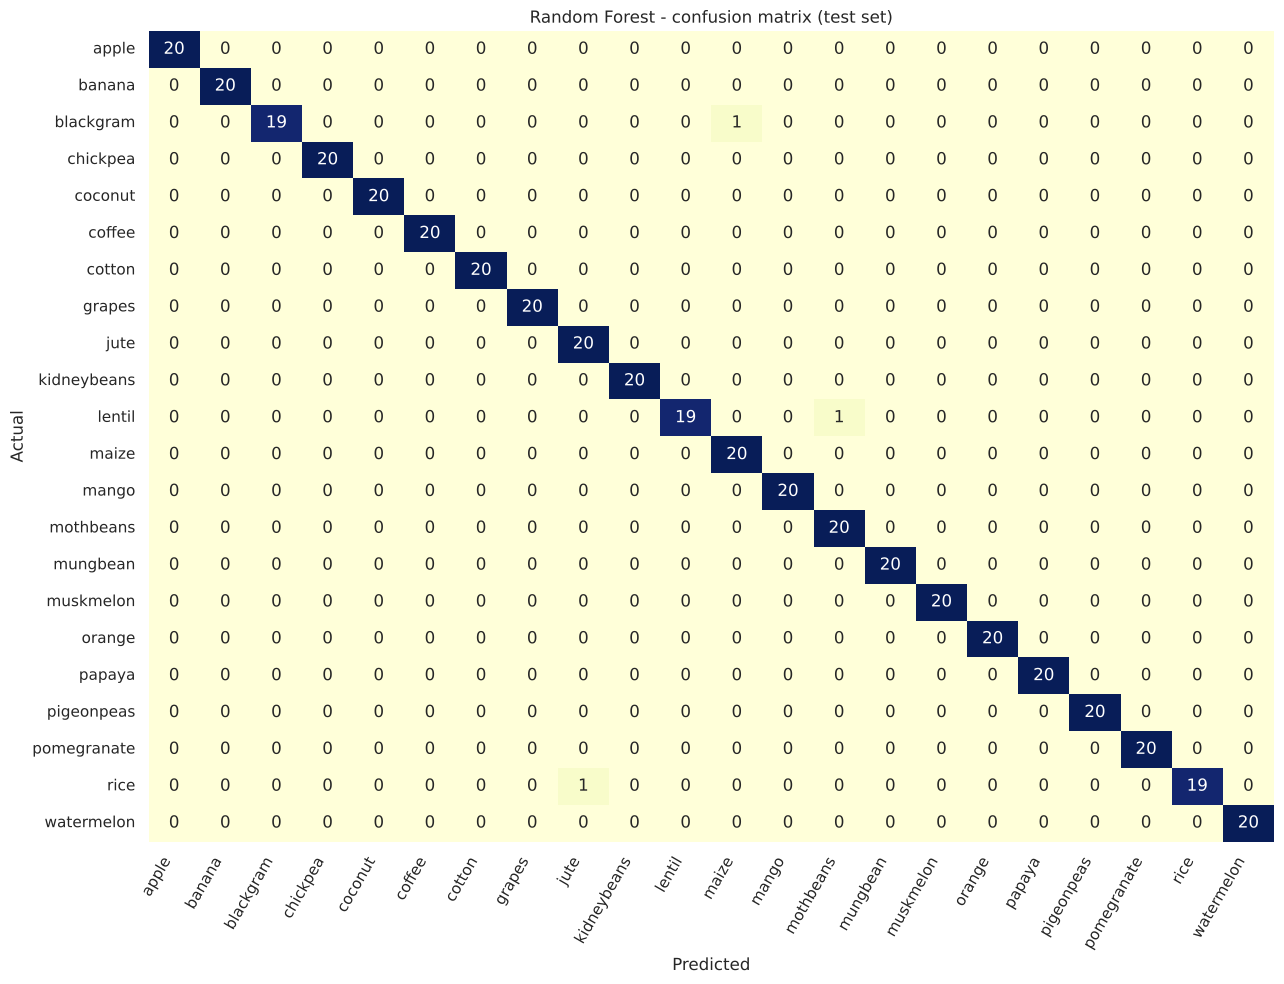

,N,P,K,temperature,humidity,ph,rainfall,actual,predicted
789,60,59,22,31.868473,66.742175,7.191523,74.222386,blackgram,maize
838,31,58,15,28.318869,60.194614,6.167855,45.365213,lentil,mothbeans
83,67,43,39,26.043720,84.969072,5.999969,186.753677,rice,jute


In [7]:
cm = confusion_matrix(y_test, pred, labels=CLASSES)
plt.figure(figsize=(13, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Random Forest - confusion matrix (test set)")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.show()

errors_df = X_test.assign(actual=y_test, predicted=pred)
display(errors_df[errors_df.actual != errors_df.predicted])

### Which features drive the model? (permutation importance)
Impurity-based `feature_importances_` (used in v1) is biased toward continuous, high-variance features. Permutation importance measures how much **log loss gets worse when one feature is shuffled** on the test set, which is closer to "how much does the model rely on this".

,feature,log-loss increase,std
4,humidity,0.9011,0.0299
6,rainfall,0.6460,0.0143
2,K,0.5900,0.0092
0,N,0.5346,0.0302
1,P,0.4940,0.0163
3,temperature,0.1737,0.0108
5,ph,0.0713,0.0040


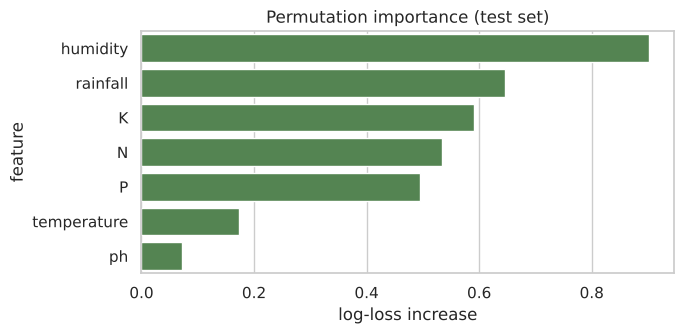

In [8]:
perm = permutation_importance(rf, X_test, y_test, scoring="neg_log_loss",
                              n_repeats=10, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({"feature": FEATURES, "log-loss increase": perm.importances_mean,
                     "std": perm.importances_std})
         .sort_values("log-loss increase", ascending=False))
display(imp.round(4))
plt.figure(figsize=(7, 3.5))
sns.barplot(data=imp, x="log-loss increase", y="feature", color="#4C8C4A")
plt.title("Permutation importance (test set)"); plt.tight_layout(); plt.show()

## 5. Probability calibration

The app will show users a probability, so it must mean what it says: among predictions made with ~80% confidence, ~80% should be right. v1 judged calibration on the 440-row test set (2 errors). Here both methods are judged on **out-of-fold probabilities for all 1,760 training rows** (nested: the calibrator inside each fold never sees that fold's held-out rows).

* **ECE** = average gap between stated confidence and actual accuracy (lower is better).
* **Log loss / Brier** = proper scoring rules for the full probability vector (lower is better).

In [9]:
def ece_top_label(conf, correct, bins=10):
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        m = (conf > lo_) & (conf <= hi_)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

def brier_multiclass(y_true, proba, classes=CLASSES):
    onehot = (np.asarray(y_true)[:, None] == classes[None, :]).astype(float)
    return np.mean(np.sum((proba - onehot) ** 2, axis=1))

def prob_report(y_true, proba):
    conf = proba.max(1); correct = CLASSES[proba.argmax(1)] == np.asarray(y_true)
    return {"accuracy": correct.mean(), "log_loss": log_loss(y_true, proba, labels=CLASSES),
            "brier": brier_multiclass(y_true, proba), "ECE": ece_top_label(conf, correct)}

cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
base_rf = lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

oof = {"raw (uncalibrated)": cross_val_predict(base_rf(), X_train, y_train, cv=cv5, method="predict_proba")}
for method in ["sigmoid", "isotonic"]:
    cal = CalibratedClassifierCV(base_rf(), method=method, cv=5)
    oof[method] = cross_val_predict(cal, X_train, y_train, cv=cv5, method="predict_proba")

cal_table = pd.DataFrame({k: prob_report(y_train, v) for k, v in oof.items()}).T
display(cal_table.style.format("{:.4f}"))

BEST_METHOD = cal_table["log_loss"].idxmin()
print("Best by log loss:", BEST_METHOD)
assert BEST_METHOD in ("sigmoid", "isotonic"), "Calibration did not help - ship the raw model instead."

,accuracy,log_loss,brier,ECE
raw (uncalibrated),0.9938,0.0601,0.0171,0.0460
sigmoid,0.9938,0.0990,0.0153,0.0843
isotonic,0.9932,0.0161,0.0090,0.0031


Best by log loss: isotonic


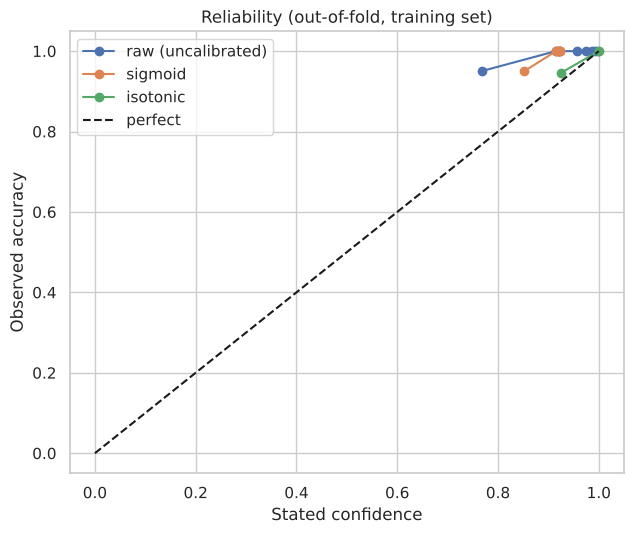

In [10]:
from sklearn.calibration import calibration_curve
plt.figure(figsize=(6.5, 5.5))
for k, p in oof.items():
    c = p.max(1); ok = CLASSES[p.argmax(1)] == y_train.values
    frac, mean = calibration_curve(ok, c, n_bins=8, strategy="quantile")
    plt.plot(mean, frac, marker="o", label=k)
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.xlabel("Stated confidence"); plt.ylabel("Observed accuracy")
plt.title("Reliability (out-of-fold, training set)"); plt.legend(); plt.tight_layout(); plt.show()

**Result.** The raw forest is *under*-confident (its vote fractions are pulled toward the middle), and sigmoid calibration makes that worse on this data. Isotonic calibration removes most of the gap. This is why v1's sigmoid experiment looked like "calibration doesn't help" - it was the wrong method, not the wrong idea.

In [11]:
final_model = CalibratedClassifierCV(base_rf(), method=BEST_METHOD, cv=5).fit(X_train, y_train)

p_raw, p_cal = rf.predict_proba(X_test), final_model.predict_proba(X_test)
test_cmp = pd.DataFrame({"raw RF": prob_report(y_test, p_raw),
                         f"RF + {BEST_METHOD}": prob_report(y_test, p_cal)}).T
f1_cal = f1_score(y_test, final_model.predict(X_test), average="macro")
display(test_cmp.style.format("{:.4f}"))
print(f"Calibrated macro-F1 on test: {f1_cal:.4f}")

,accuracy,log_loss,brier,ECE
raw RF,0.9932,0.0527,0.0153,0.0398
RF + isotonic,0.9909,0.0177,0.0110,0.0054


Calibrated macro-F1 on test: 0.9909


Calibration costs one extra test error here (4 vs 3 of 440; each calibrated sub-model sees 80% of the data, and a one-row difference is inside sampling noise) for roughly 3x better probability quality. For a product whose selling point is *communicating uncertainty*, that is the right trade.

## 6. Low-confidence rule (derived from training data, not the test set)

Rule: *flag a prediction as low confidence if calibrated top probability < t.* We pick the **smallest t for which predictions above t were at least 99.8% correct in out-of-fold training data**. That makes the rule explainable: "when the app is confident, it was right about 99.8% of the time in cross-validation." The test-set check below is an independent sanity check; with only 440 rows its accuracy estimate is coarse (one extra error moves it by 0.2 points), so read it as "consistent", not as a guarantee.

In [12]:
p_oof = oof[BEST_METHOD]
conf_oof = p_oof.max(1); ok_oof = CLASSES[p_oof.argmax(1)] == y_train.values

grid = np.round(np.arange(0.40, 0.96, 0.05), 2)
thr_table = pd.DataFrame([{
    "threshold": t,
    "flagged %": 100 * (conf_oof < t).mean(),
    "accuracy of accepted %": 100 * ok_oof[conf_oof >= t].mean(),
    "errors caught": f"{int(((conf_oof < t) & ~ok_oof).sum())}/{int((~ok_oof).sum())}",
} for t in grid])
display(thr_table.style.format({"flagged %": "{:.1f}", "accuracy of accepted %": "{:.2f}"}))

TARGET_ACCEPTED_ACC = 0.998
eligible = [t for t in grid if ok_oof[conf_oof >= t].mean() >= TARGET_ACCEPTED_ACC]
CONF_THRESHOLD = float(min(eligible))
print(f"Chosen low-confidence threshold: {CONF_THRESHOLD}")

,threshold,flagged %,accuracy of accepted %,errors caught
0,0.400000,0.0,99.32,0/12
1,0.450000,0.1,99.37,1/12
2,0.500000,0.1,99.37,1/12
3,0.550000,0.3,99.49,3/12
4,0.600000,0.6,99.60,5/12
5,0.650000,0.8,99.66,6/12
6,0.700000,1.1,99.77,8/12
7,0.750000,1.3,99.88,10/12
8,0.800000,1.5,99.88,10/12
9,0.850000,1.9,99.94,11/12


Chosen low-confidence threshold: 0.75


In [13]:
# One-time check on the test set (threshold was NOT tuned on it)
conf_te = p_cal.max(1); ok_te = CLASSES[p_cal.argmax(1)] == y_test.values
acc_mask = conf_te >= CONF_THRESHOLD
print(f"Test: flagged {100*(~acc_mask).mean():.1f}% of rows | accuracy of accepted rows "
      f"{100*ok_te[acc_mask].mean():.2f}% | errors caught {int((~acc_mask & ~ok_te).sum())}/{int((~ok_te).sum())}")

Test: flagged 0.7% of rows | accuracy of accepted rows 99.54% | errors caught 2/4


## 7. Unusual-input detection

**Why not a global Isolation Forest (v1 first attempt).** Grapes legitimately have K around 200 and P around 130; no other crop does. A global detector sees "K=200" as rare and flags it, so 10 of its 12 flags were healthy grape samples. The question the app needs answered is *"is this input unusual for the crop we are about to recommend?"*, so detectors are per crop.

**Why Mahalanobis instead of per-crop Isolation Forest.** With about 80 rows per crop in 7 dimensions, Isolation Forest is a weak, noisy density estimator and its `contamination=0.05` makes it flag 5% of *training* rows by construction (and ~15% of unseen normal rows). A Mahalanobis distance with a shrinkage covariance (Ledoit-Wolf) uses the correlation between nutrients and weather, is stable at small sample sizes, and its threshold can be set directly from held-out data: here, the 98th percentile of held-out distances per crop, so about 2% false flags by design.

In [14]:
def fit_mahalanobis(Xa, ya):
    det = {}
    for crop in CLASSES:
        Z = Xa[ya == crop][FEATURES].values
        lw = LedoitWolf().fit(Z)
        det[crop] = {"mean": lw.location_, "precision": lw.get_precision()}
    return det

def mahal_d2(det, crop, A):
    diff = np.atleast_2d(A) - det[crop]["mean"]
    return np.einsum("ij,jk,ik->i", diff, det[crop]["precision"], diff)

# Thresholds from HELD-OUT distances (fit on 4 folds, score the 5th, true class)
held = {c: [] for c in CLASSES}
for tr_idx, va_idx in cv5.split(X_train, y_train):
    d = fit_mahalanobis(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    Xv, yv = X_train.iloc[va_idx], y_train.iloc[va_idx]
    for crop in CLASSES:
        held[crop] += list(mahal_d2(d, crop, Xv[yv == crop][FEATURES].values))

OOD_PERCENTILE = 98
detectors = fit_mahalanobis(X_train, y_train)          # final detectors use all training rows
for crop in CLASSES:
    detectors[crop]["threshold"] = float(np.percentile(held[crop], OOD_PERCENTILE))

print("Squared-distance thresholds (first 6 crops):",
      {c: round(detectors[c]["threshold"], 1) for c in CLASSES[:6]})

Squared-distance thresholds (first 6 crops): {'apple': 10.9, 'banana': 9.9, 'blackgram': 12.9, 'chickpea': 11.0, 'coconut': 8.8, 'coffee': 12.1}


In [15]:
# Fair comparison of detectors: false-flag rate on real test rows, detection rate on synthetic junk
def flag_maha(Xa, crops):
    out = np.zeros(len(Xa), bool)
    for crop in np.unique(crops):
        m = crops == crop
        out[m] = mahal_d2(detectors, crop, Xa[m]) > detectors[crop]["threshold"]
    return out

def fit_if(cont):
    d = {}
    for crop in CLASSES:
        Z = X_train[y_train == crop].values
        sc = StandardScaler().fit(Z)
        d[crop] = (sc, IsolationForest(n_estimators=200, contamination=cont, random_state=SEED).fit(sc.transform(Z)))
    return d

def flag_if(d, Xa, crops):
    out = np.zeros(len(Xa), bool)
    for crop in np.unique(crops):
        m = crops == crop
        sc, mdl = d[crop]
        out[m] = mdl.predict(sc.transform(Xa[m])) == -1
    return out

# Synthetic junk 1: random points inside the training min/max box (plausible per-feature, implausible together)
rng = np.random.default_rng(0)
lo_, hi_ = X_train.min().values, X_train.max().values
junk_box = rng.uniform(lo_, hi_, size=(2000, len(FEATURES)))
# Synthetic junk 2: the 5 hand-made corner cases from v1
junk_corner = np.array([[140,5,205,10,15,3.5,25],[0,145,5,43,99,9.9,298],[135,10,200,42,20,9.5,25],
                        [5,140,10,9,98,3.6,290],[130,5,5,40,15,9.8,280]], float)

Xte_a = X_test[FEATURES].values
as_df = lambda A: pd.DataFrame(A, columns=FEATURES)
crop_te, crop_box, crop_cor = (final_model.classes_[final_model.predict_proba(as_df(A)).argmax(1)]
                               for A in (Xte_a, junk_box, junk_corner))

rows = []
for label, fn in [("Mahalanobis (98th pct)", lambda A, c: flag_maha(A, c)),
                  ("Isolation Forest, contamination 0.05 (v1)", lambda A, c, d=fit_if(0.05): flag_if(d, A, c)),
                  ("Isolation Forest, contamination 0.01", lambda A, c, d=fit_if(0.01): flag_if(d, A, c))]:
    rows.append({"Detector": label,
                 "False flags on real test rows %": 100 * fn(Xte_a, crop_te).mean(),
                 "Caught: random in-box junk %": 100 * fn(junk_box, crop_box).mean(),
                 "Caught: 5 corner cases": f"{int(fn(junk_corner, crop_cor).sum())}/5"})
display(pd.DataFrame(rows).style.format({"False flags on real test rows %": "{:.1f}",
                                         "Caught: random in-box junk %": "{:.1f}"}))

,Detector,False flags on real test rows %,Caught: random in-box junk %,Caught: 5 corner cases
0,Mahalanobis (98th pct),1.6,99.7,5/5
1,"Isolation Forest, contamination 0.05 (v1)",12.3,97.4,5/5
2,"Isolation Forest, contamination 0.01",4.1,93.8,5/5


The v1 detector wrongly flags roughly 1 in 8 normal inputs; the Mahalanobis detector flags about 1 in 60 while catching essentially all of the implausible mixtures. These "junk" sets are crude proxies for real-world bad data (real farmer errors - unit mix-ups, copied lab values - will differ), so treat the catch rates as an upper bound, and re-evaluate once real field inputs exist.

## 8. Input validation and the full decision function

One function, `assess_input`, is the entire inference path. It takes only the loaded artifacts (model, metadata, detectors) - nothing from this notebook's globals - so the same code can be pasted into FastAPI.

**Decision policy** (first matching rule wins):

| Status | Trigger | App behaviour |
|---|---|---|
| `invalid` | Missing, non-numeric, non-finite, or physically impossible value | No prediction; return the error list |
| `out_of_range` | Any feature outside the training min/max | No recommendation; warn which feature |
| `unusual_input` | Mahalanobis distance to the predicted crop above its threshold | No recommendation; say the combination is atypical |
| `low_confidence` | Calibrated top probability below the threshold | No single recommendation; show top-3 candidates |
| `ok` | None of the above | Recommend top crop, show top-3 with probabilities |

In [16]:
PHYSICAL_BOUNDS = {            # hard limits: outside these the value cannot be real
    "N": (0, None), "P": (0, None), "K": (0, None),
    "temperature": (-10, 60), "humidity": (0, 100), "ph": (0, 14), "rainfall": (0, None),
}

def validate_input(raw, meta):
    """Returns (clean_values or None, errors, range_warnings)."""
    errors, warns, clean = [], [], {}
    for f in meta["features"]:
        if f not in raw or raw[f] is None:
            errors.append(f"Missing input: {f}"); continue
        try:
            v = float(raw[f])
        except (TypeError, ValueError):
            errors.append(f"{f} must be numeric"); continue
        if not np.isfinite(v):
            errors.append(f"{f} must be a finite number"); continue
        lo_b, hi_b = meta["physical_bounds"][f]
        if (lo_b is not None and v < lo_b) or (hi_b is not None and v > hi_b):
            errors.append(f"{f}={v:g} is physically impossible (allowed {lo_b} to {hi_b if hi_b is not None else 'no upper limit'})")
            continue
        clean[f] = v
    if errors:
        return None, errors, warns
    for f, v in clean.items():
        r = meta["training_ranges"][f]
        if v < r["min"] or v > r["max"]:
            warns.append(f"{f}={v:g} is outside the range the model was trained on ({r['min']:.3f} to {r['max']:.3f})")
    return clean, errors, warns


def assess_input(raw, model, meta, detectors, top_k=3):
    clean, errors, range_warns = validate_input(raw, meta)
    if errors:
        return {"status": "invalid", "recommendation": None, "errors": errors}

    x = pd.DataFrame([[clean[f] for f in meta["features"]]], columns=meta["features"])
    proba = model.predict_proba(x)[0]
    order = np.argsort(proba)[::-1][:top_k]
    top = [{"crop": str(model.classes_[i]), "probability": round(float(proba[i]), 3)} for i in order]
    pred, conf = top[0]["crop"], float(proba[order[0]])

    det = detectors[pred]
    diff = x.values[0] - det["mean"]
    d2 = float(diff @ det["precision"] @ diff)
    unusual = d2 > det["threshold"]

    reasons = list(range_warns)
    if unusual:
        reasons.append(f"This combination is atypical for {pred} (distance {d2:.1f} vs limit {det['threshold']:.1f})")
    low_conf = conf < meta["thresholds"]["low_confidence"]
    if low_conf:
        reasons.append(f"Model confidence {conf:.0%} is below {meta['thresholds']['low_confidence']:.0%}")

    if range_warns:                 status = "out_of_range"
    elif unusual:                   status = "unusual_input"
    elif low_conf:                  status = "low_confidence"
    else:                           status = "ok"

    return {"status": status,
            "recommendation": pred if status == "ok" else None,
            "top_candidates": top if status in ("ok", "low_confidence") else None,
            "confidence": round(conf, 3), "reasons": reasons}

## 9. Save artifacts and verify the round trip

Same file names as v1 so existing code keeps working, but the contents changed (calibrated model; Mahalanobis detectors stored as plain NumPy arrays, which carry no `sklearn` pickle risk). A readable `model_metadata.json` is saved next to the pickle.

In [17]:
# Avoid spawning a thread pool for every single-row API call (raise n_jobs again if you batch)
for cc in final_model.calibrated_classifiers_:
    cc.estimator.set_params(n_jobs=1)

metadata = {
    "model_name": f"Random Forest (300 trees) + {BEST_METHOD} calibration",
    "features": FEATURES,
    "classes": [str(c) for c in final_model.classes_],
    "training_ranges": {f: {"min": float(X_train[f].min()), "max": float(X_train[f].max())} for f in FEATURES},
    "physical_bounds": PHYSICAL_BOUNDS,
    "thresholds": {"low_confidence": CONF_THRESHOLD,
                   "unusual_input": f"per-crop squared Mahalanobis, {OOD_PERCENTILE}th percentile of held-out distances"},
    "training": {"n_train": int(len(X_train)), "n_test": int(len(X_test)), "random_state": SEED,
                 "test_accuracy": round(float(accuracy_score(y_test, final_model.predict(X_test))), 4),
                 "test_macro_f1": round(float(f1_cal), 4)},
    "versions": {"sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}

joblib.dump(final_model, MODEL_DIR / "crop_recommendation_model.pkl", compress=3)
joblib.dump(metadata,    MODEL_DIR / "model_metadata.pkl")
joblib.dump(detectors,   MODEL_DIR / "class_anomaly_detectors.pkl")
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved:", *sorted(p.name for p in MODEL_DIR.iterdir()), sep="\n  ")

Saved:
  class_anomaly_detectors.pkl
  crop_recommendation_model.pkl
  model_metadata.json
  model_metadata.pkl


In [18]:
# Reload from disk exactly as the API will, and prove the saved model behaves like the in-memory one
m2   = joblib.load(MODEL_DIR / "crop_recommendation_model.pkl")
meta2 = joblib.load(MODEL_DIR / "model_metadata.pkl")
det2 = joblib.load(MODEL_DIR / "class_anomaly_detectors.pkl")

assert meta2["versions"]["sklearn"] == sklearn.__version__, "sklearn version mismatch with saved model"
assert list(m2.classes_) == meta2["classes"] and meta2["features"] == FEATURES
assert np.allclose(m2.predict_proba(X_test), final_model.predict_proba(X_test)), "reload changed predictions"
print("Round trip OK")

Round trip OK


## 10. Scenario tests on the reloaded artifacts

In [19]:
def show(title, raw):
    t0 = time.perf_counter(); r = assess_input(raw, m2, meta2, det2); ms = 1000 * (time.perf_counter() - t0)
    print(f"{title:<34} -> {r['status']:<14} rec={r['recommendation']}  ({ms:.0f} ms)")
    for k in ("errors", "reasons"):
        for msg in r.get(k, []) or []:
            print("     -", msg)
    return r

typical = dict(N=90, P=42, K=43, temperature=20.9, humidity=82.0, ph=6.5, rainfall=203)
show("Typical rice-like input", typical)
show("Rainfall 350 (outside training)", {**typical, "rainfall": 350})
show("pH 15 (impossible)", {**typical, "ph": 15})
show("Missing humidity + text N", {k: v for k, v in {**typical, "N": "abc"}.items() if k != "humidity"})
show("Corner case 1", dict(zip(FEATURES, [140, 5, 205, 10, 15, 3.5, 25])))
show("Corner case 5", dict(zip(FEATURES, [130, 5, 5, 40, 15, 9.8, 280])))

# the least confident real test row: expect low_confidence or unusual_input, not a silent recommendation
lc = X_test.iloc[[int(np.argmin(p_cal.max(1)))]].iloc[0].to_dict()
r = show("Least confident real test row", lc); print("     candidates:", r["top_candidates"])

Typical rice-like input            -> ok             rec=rice  (82 ms)
Rainfall 350 (outside training)    -> out_of_range   rec=None  (93 ms)
     - rainfall=350 is outside the range the model was trained on (20.211 to 298.560)
     - This combination is atypical for rice (distance 14.7 vs limit 8.5)
pH 15 (impossible)                 -> invalid        rec=None  (0 ms)
     - ph=15 is physically impossible (allowed 0 to 14)
Missing humidity + text N          -> invalid        rec=None  (0 ms)
     - N must be numeric
     - Missing input: humidity


Corner case 1                      -> out_of_range   rec=None  (92 ms)
     - ph=3.5 is outside the range the model was trained on (3.505 to 9.935)
     - This combination is atypical for muskmelon (distance 4667.8 vs limit 10.7)
     - Model confidence 40% is below 75%


Corner case 5                      -> unusual_input  rec=None  (96 ms)
     - This combination is atypical for coffee (distance 177.4 vs limit 12.1)
     - Model confidence 65% is below 75%


Least confident real test row      -> low_confidence rec=None  (141 ms)
     - Model confidence 55% is below 75%
     candidates: [{'crop': 'mothbeans', 'probability': 0.547}, {'crop': 'lentil', 'probability': 0.451}, {'crop': 'mungbean', 'probability': 0.002}]


In [20]:
# End-to-end policy on the whole test set, through the SAME function the API will use
recs = [assess_input(row.to_dict(), m2, meta2, det2) for _, row in X_test.iterrows()]
policy = pd.DataFrame({"status": [r["status"] for r in recs],
                       "pred": [r["top_candidates"][0]["crop"] if r["top_candidates"] else None for r in recs],
                       "actual": y_test.values})
policy["correct"] = policy.pred == policy.actual
print("Status counts on real test rows:"); print(policy.status.value_counts().to_string())
ok_rows = policy[policy.status == "ok"]
print(f"\nRecommendations given: {len(ok_rows)}/{len(policy)} ({100*len(ok_rows)/len(policy):.1f}%) "
      f"| accuracy of those recommendations: {100*ok_rows.correct.mean():.2f}%")

# Same function on synthetic junk: how often does the app refuse to recommend?
sub = pd.DataFrame(junk_box[:300], columns=FEATURES)
junk_status = pd.Series([assess_input(r.to_dict(), m2, meta2, det2)["status"] for _, r in sub.iterrows()])
print(f"\nRandom in-box junk (300 rows): app recommended on {100*(junk_status=='ok').mean():.1f}% of them")

Status counts on real test rows:
status
ok                430
unusual_input       7
low_confidence      3

Recommendations given: 430/440 (97.7%) | accuracy of those recommendations: 99.77%



Random in-box junk (300 rows): app recommended on 0.3% of them


## 11. Known limits (read before building the next features)

1. **Accuracy is saturated; the dataset is the ceiling.** All strong models land at about 99%+ because crop classes in this dataset are separated by narrow, mostly non-overlapping ranges. This does not mean 99% accuracy on real farms. Real fields will overlap far more, which is exactly why the confidence and unusual-input layers matter more than another 0.1% accuracy.
2. **Units and scale of N, P, K are undocumented in this file** (N 0-140, P 5-145, K 5-205). If the app asks farmers to enter lab or Soil Health Card values, confirm those are on the same scale as this data; if not, the out-of-range check will (correctly) reject most real inputs.
3. **Scope.** This dataset has no state, season, soil type, EC or organic carbon, and it includes crops that are not normally grown in Telangana. Those belong to the planned dataset / feature work and are not handled here.
4. **Thresholds are estimates.** Confidence threshold rests on about 12 out-of-fold errors; the unusual-input threshold on about 80 rows per crop. Re-derive both whenever the dataset or features change (this notebook does that automatically).
5. **Test set is now used.** For any further model changes, use cross-validation on the training split, and treat the test set as spent or collect fresh data.